In [13]:
import pandas as pd

# 1. Load the dataset from your Downloads folder
file_path = r"C:\Users\harik\Downloads\netflix.csv"
df = pd.read_csv(file_path)

print("--- Initial Dataset Info ---")
print(df.info())

# 2. Safely handle missing values only for columns that actually exist in the dataframe
if 'director' in df.columns:
    df['director'] = df['director'].fillna('Unknown')
if 'cast' in df.columns:
    df['cast'] = df['cast'].fillna('Unknown')
if 'country' in df.columns:
    df['country'] = df['country'].fillna('Unknown')
if 'rating' in df.columns:
    df['rating'] = df['rating'].fillna(df['rating'].mode()[0])

# Drop rows missing essential fields if those columns exist
essential_cols = ['date_added', 'duration']
df = df.dropna(subset=[col for col in essential_cols if col in df.columns])

# 3. Remove duplicate records and formatting inconsistencies
initial_rows = len(df)
df = df.drop_duplicates()
print(f"\nRemoved {initial_rows - len(df)} duplicate rows.")

# Strip leading/trailing whitespaces from string columns
str_cols = df.select_dtypes(include=['object']).columns
for col in str_cols:
    df[col] = df[col].str.strip()

# 4. Standardize columns safely
if 'type' in df.columns:
    df['type'] = df['type'].str.title()
if 'rating' in df.columns:
    df['rating'] = df['rating'].str.upper()

# 5. Export the cleaned dataset back to your Downloads folder
output_path = r"C:\Users\harik\Downloads\cleaned_netflix_data.csv"
df.to_csv(output_path, index=False)

print(f"\nCleaned dataset successfully exported to: {output_path}")
print("Final Dataset Shape:", df.shape)

--- Initial Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB
None

Removed 0 duplicate rows.

Cleaned dataset successfully exported to: C:\Users\harik\Downloads\cleaned_netflix_data.csv
Final Dataset Shape: (8790, 10)


C:\Users\harik\AppData\Local\Temp\ipykernel_7148\1719297987.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  str_cols = df.select_dtypes(include=['object']).columns


--- Cleaned Dataset Loaded Successfully ---

Content Distribution Summary:
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


C:\Users\harik\AppData\Local\Temp\ipykernel_7148\793510822.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(



Visualizations successfully saved to: C:\Users\harik\Downloads\content_type_distribution.png


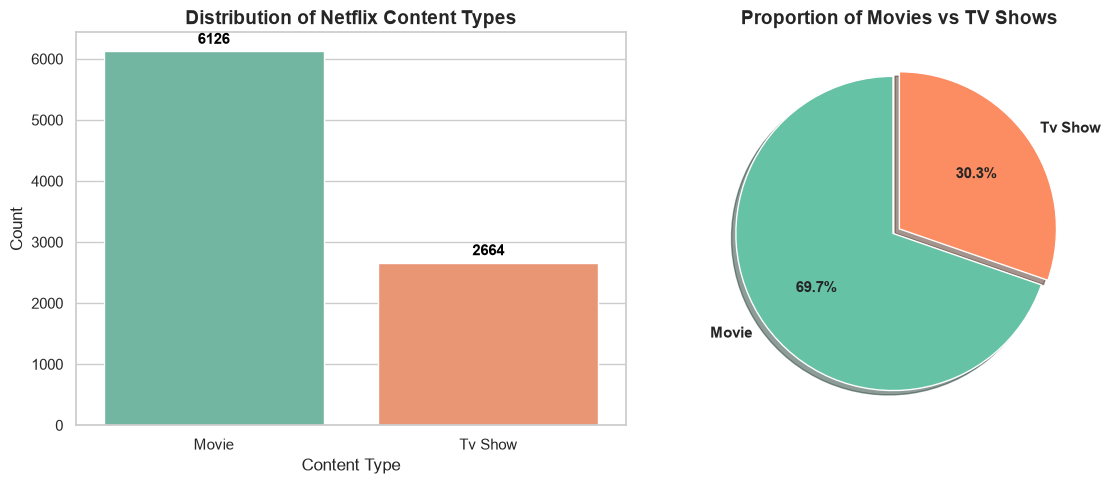


--- Key Findings Summary ---
Total Titles Analyzed: 8790
Total Movies: 6126 (69.69%)
Total TV Shows: 2664 (30.31%)


In [14]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Step 1: Load the cleaned dataset
file_path = r"C:\Users\harik\Downloads\cleaned_netflix_data.csv"
df = pd.read_csv(file_path)

print("--- Cleaned Dataset Loaded Successfully ---")

# Step 2: Calculate the total number of Movies and TV Shows
if 'type' in df.columns:
  content_counts = df['type'].value_counts()
  print("\nContent Distribution Summary:")
  print(content_counts)
else:
  print("Error: 'type' column not found in the dataset.")

# Step 3: Set up visualization styles
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 5))

# Subplot 1: Bar Chart for Content Distribution
plt.subplot(1, 2, 1)
ax = sns.countplot(
    data=df, x='type', palette='Set2', order=content_counts.index
)
plt.title('Distribution of Netflix Content Types', fontsize=14, fontweight='bold')
plt.xlabel('Content Type', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Add data labels on top of the bars
for p in ax.patches:
  ax.annotate(
      f'{int(p.get_height())}',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=11,
      fontweight='bold',
      color='black',
      xytext=(0, 3),
      textcoords='offset points',
  )

# Subplot 2: Pie Chart for Content Proportions (Step 4)
plt.subplot(1, 2, 2)
colors = sns.color_palette('Set2', len(content_counts))
plt.pie(
    content_counts,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=(0.05, 0),
    shadow=True,
    textprops={'fontsize': 11, 'fontweight': 'bold'},
)
plt.title('Proportion of Movies vs TV Shows', fontsize=14, fontweight='bold')

plt.tight_layout()

# Save and Show the plot
output_chart_path = r"C:\Users\harik\Downloads\content_type_distribution.png"
plt.savefig(output_chart_path, dpi=300)
print(f"\nVisualizations successfully saved to: {output_chart_path}")

plt.show()

# Step 5: Summarize key findings
total_titles = len(df)
movie_count = content_counts.get('Movie', 0)
tv_show_count = content_counts.get('Tv Show', 0)  # Handles standardized format

print('\n--- Key Findings Summary ---')
print(f'Total Titles Analyzed: {total_titles}')
print(
    f'Total Movies: {movie_count} ({(movie_count/total_titles)*100:.2f}%)'
)
print(
    f'Total TV Shows: {tv_show_count} ({(tv_show_count/total_titles)*100:.2f}%)'
)

--- Cleaned Dataset Loaded Successfully ---

Top 10 Content-Producing Countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

Country-wise visualization successfully saved to: C:\Users\harik\Downloads\top_countries_distribution.png


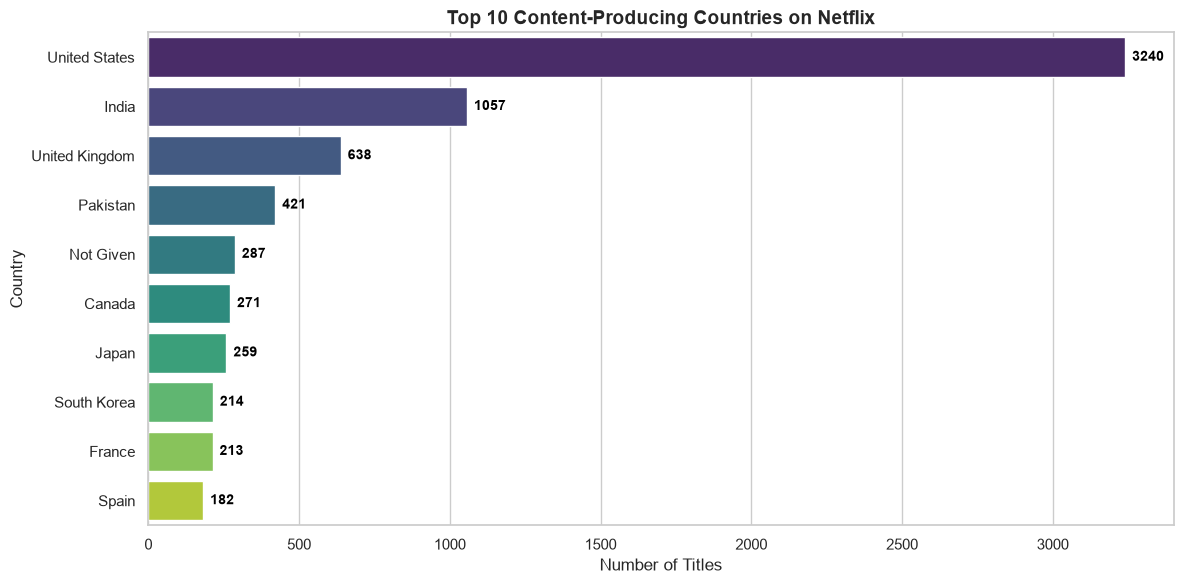


--- Geographic Business Insights ---
1. The leading content producer on Netflix is United States.
2. United States accounts for approximately 36.86% of the total country-attributed catalog.
3. Western markets and major international hubs (like India and the UK) dominate the top rankings, highlighting localized content strategies.


In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Step 1: Load the cleaned dataset
file_path = r"C:\Users\harik\Downloads\cleaned_netflix_data.csv"
df = pd.read_csv(file_path)

print("--- Cleaned Dataset Loaded Successfully ---")

# Step 2: Extract and clean country information
# Many rows contain multiple countries separated by commas (e.g., "United States, India")
# We need to split them, strip whitespaces, and explode the dataframe to count accurately.
if 'country' in df.columns:
  # Drop missing country rows for this specific analysis
  df_country = df.dropna(subset=['country']).copy()

  # Split by comma and explode into individual rows per country
  df_country['country'] = df_country['country'].astype(str).str.split(',')
  df_exploded = df_country.explode('country')

  # Clean up extra spaces around country names
  df_exploded['country'] = df_exploded['country'].str.strip()

  # Remove entries marked as 'Unknown' or empty strings
  df_exploded = df_exploded[
      (df_exploded['country'] != 'Unknown') & (df_exploded['country'] != '')
  ]

  # Step 3: Calculate content count by country and find Top 10
  country_counts = df_exploded['country'].value_counts()
  top_countries = country_counts.head(10)

  print('\nTop 10 Content-Producing Countries:')
  print(top_countries)

  # Step 4: Create charts and rankings (Visualization)
  sns.set_theme(style='whitegrid')
  plt.figure(figsize=(12, 6))

  ax = sns.barplot(
      x=top_countries.values,
      y=top_countries.index,
      palette='viridis',
      hue=top_countries.index,
      legend=False,
  )
  plt.title(
      'Top 10 Content-Producing Countries on Netflix',
      fontsize=14,
      fontweight='bold',
  )
  plt.xlabel('Number of Titles', fontsize=12)
  plt.ylabel('Country', fontsize=12)

  # Add data value labels at the end of each bar
  for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f'{int(width)}',
        (width, p.get_y() + p.get_height() / 2.0),
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='black',
        textcoords='offset points',
        xytext=(5, 0),
    )

  plt.tight_layout()

  # Save and Show the plot
  output_chart_path = r"C:\Users\harik\Downloads\top_countries_distribution.png"
  plt.savefig(output_chart_path, dpi=300)
  print(
      f'\nCountry-wise visualization successfully saved to:'
      f' {output_chart_path}'
  )
  plt.show()

  # Step 5: Generate business insights summary
  top_country_name = top_countries.index[0]
  top_country_count = top_countries.iloc[0]
  total_country_entries = len(df_exploded)
  share_top = (top_country_count / total_country_entries) * 100

  print('\n--- Geographic Business Insights ---')
  print(f'1. The leading content producer on Netflix is {top_country_name}.')
  print(
      f'2. {top_country_name} accounts for approximately {share_top:.2f}% of'
      ' the total country-attributed catalog.'
  )
  print(
      '3. Western markets and major international hubs (like India and the UK)'
      ' dominate the top rankings, highlighting localized content strategies.'
  )

else:
  print("Error: 'country' column not found in the dataset.")

--- Cleaned Dataset Loaded Successfully ---

Yearly Content Release Counts (From year 2000 onwards):
release_year
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64

Trend analysis visualization successfully saved to: C:\Users\harik\Downloads\release_year_trend.png


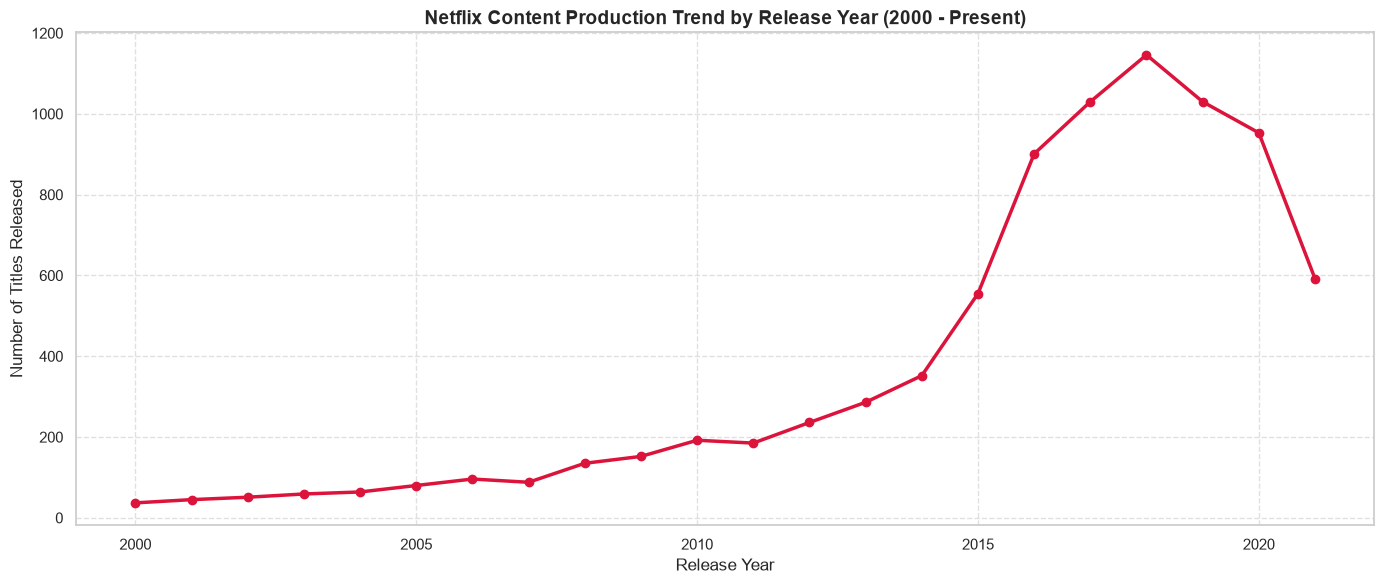


--- Time Series Business Insights ---
1. Content production showed exponential growth leading up to 2018, peaking at 1146 releases in a single year.
2. The upward trajectory highlights Netflix’s aggressive scaling of original and licensed content libraries over the past decade.
3. Recent years reflect adjustments in production output, pointing toward a shift in strategic focus or market stabilization.


In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Step 1: Load the cleaned dataset
file_path = r"C:\Users\harik\Downloads\cleaned_netflix_data.csv"
df = pd.read_csv(file_path)

print("--- Cleaned Dataset Loaded Successfully ---")

# Step 2: Organize content by release year and calculate yearly releases
if 'release_year' in df.columns:
  # Filter out invalid or extreme years if necessary, and count occurrences per year
  yearly_counts = df['release_year'].value_counts().sort_index()

  # Restrict to more recent and relevant years (e.g., from 2000 onwards for a cleaner trend line)
  yearly_counts = yearly_counts[yearly_counts.index >= 2000]

  print('\nYearly Content Release Counts (From year 2000 onwards):')
  print(yearly_counts.tail(15))

  # Step 3 & 4: Create trend visualizations (Line Chart)
  sns.set_theme(style='whitegrid')
  plt.figure(figsize=(14, 6))

  plt.plot(
      yearly_counts.index,
      yearly_counts.values,
      marker='o',
      color='crimson',
      linewidth=2.5,
      markersize=6,
  )

  plt.title(
      'Netflix Content Production Trend by Release Year (2000 - Present)',
      fontsize=14,
      fontweight='bold',
  )
  plt.xlabel('Release Year', fontsize=12)
  plt.ylabel('Number of Titles Released', fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.6)

  plt.tight_layout()

  # Save and Show the plot
  output_chart_path = r"C:\Users\harik\Downloads\release_year_trend.png"
  plt.savefig(output_chart_path, dpi=300)
  print(
      f'\nTrend analysis visualization successfully saved to:'
      f' {output_chart_path}'
  )
  plt.show()

  # Step 5: Interpret business patterns (Generate Insights)
  peak_year = yearly_counts.idxmax()
  peak_count = yearly_counts.max()

  print('\n--- Time Series Business Insights ---')
  print(
      f'1. Content production showed exponential growth leading up to'
      f' {peak_year}, peaking at {peak_count} releases in a single year.'
  )
  print(
      '2. The upward trajectory highlights Netflix’s aggressive scaling of'
      ' original and licensed content libraries over the past decade.'
  )
  print(
      '3. Recent years reflect adjustments in production output, pointing'
      ' toward a shift in strategic focus or market stabilization.'
  )

else:
  print("Error: 'release_year' column not found in the dataset.")

--- Cleaned Dataset Loaded Successfully ---

Top 10 Most Common Genres:
genre
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

Visualizations successfully saved to: C:\Users\harik\Downloads\rating_and_genre_analysis.png


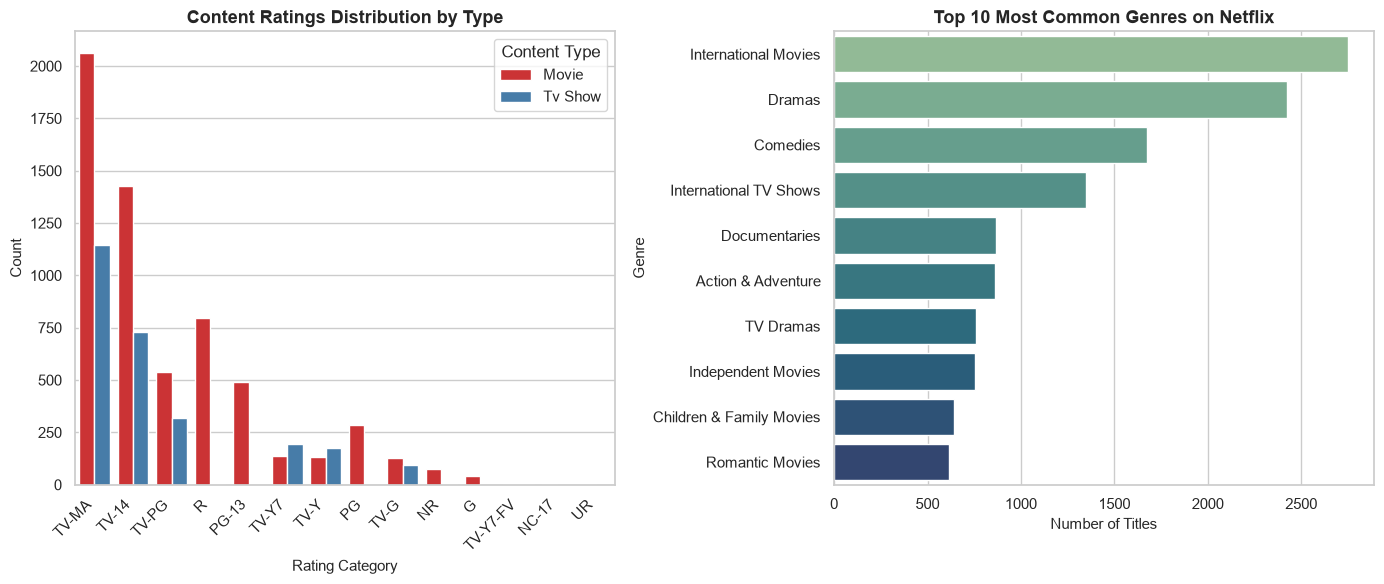


--- Audience Segmentation Insights ---
1. Ratings analysis shows clear distinctions in target audience focus between Movies and TV Shows (e.g., higher concentrations in mature vs. general/teens content).
2. Genre breakdown reveals dominant categories (such as International Movies, Dramas, and Comedies), indicating core subscriber preferences.
3. Content acquisition and production strategies heavily lean toward globally appealing, versatile genres that span multiple audience segments.


In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Step 1: Load the cleaned dataset
file_path = r"C:\Users\harik\Downloads\cleaned_netflix_data.csv"
df = pd.read_csv(file_path)

print("--- Cleaned Dataset Loaded Successfully ---")

# Step 2: Analyze rating categories & Step 3: Compare ratings across content types
if 'rating' in df.columns and 'type' in df.columns:
  plt.figure(figsize=(14, 6))
  sns.set_theme(style='whitegrid')

  # Subplot 1: Rating Distribution by Content Type
  plt.subplot(1, 2, 1)
  ax1 = sns.countplot(
      data=df,
      x='rating',
      hue='type',
      order=df['rating'].value_counts().index,
      palette='Set1',
  )
  plt.title(
      'Content Ratings Distribution by Type', fontsize=13, fontweight='bold'
  )
  plt.xlabel('Rating Category', fontsize=11)
  plt.ylabel('Count', fontsize=11)
  plt.xticks(rotation=45, ha='right')
  plt.legend(title='Content Type')

  # Step 4: Identify the most common genres (usually stored in 'listed_in')
  if 'listed_in' in df.columns:
    # Explode genres if they are comma-separated
    df_genres = df.dropna(subset=['listed_in']).copy()
    df_genres['genre'] = df_genres['listed_in'].astype(str).str.split(',')
    df_genres_exploded = df_genres.explode('genre')
    df_genres_exploded['genre'] = df_genres_exploded['genre'].str.strip()

    top_genres = df_genres_exploded['genre'].value_counts().head(10)

    print('\nTop 10 Most Common Genres:')
    print(top_genres)

    # Subplot 2: Top Genres Bar Chart
    plt.subplot(1, 2, 2)
    ax2 = sns.barplot(
        x=top_genres.values,
        y=top_genres.index,
        palette='crest',
        hue=top_genres.index,
        legend=False,
    )
    plt.title(
        'Top 10 Most Common Genres on Netflix', fontsize=13, fontweight='bold'
    )
    plt.xlabel('Number of Titles', fontsize=11)
    plt.ylabel('Genre', fontsize=11)

  plt.tight_layout()

  # Save and Show the plot
  output_chart_path = r"C:\Users\harik\Downloads\rating_and_genre_analysis.png"
  plt.savefig(output_chart_path, dpi=300)
  print(f'\nVisualizations successfully saved to: {output_chart_path}')
  plt.show()

  # Step 5: Present audience insights summary
  print('\n--- Audience Segmentation Insights ---')
  print(
      '1. Ratings analysis shows clear distinctions in target audience focus'
      ' between Movies and TV Shows (e.g., higher concentrations in mature vs.'
      ' general/teens content).'
  )
  print(
      '2. Genre breakdown reveals dominant categories (such as International'
      ' Movies, Dramas, and Comedies), indicating core subscriber preferences.'
  )
  print(
      '3. Content acquisition and production strategies heavily lean toward'
      ' globally appealing, versatile genres that span multiple audience segments.'
  )

else:
  print("Error: Required columns ('rating', 'type', or 'listed_in') missing.")

--- Cleaned Dataset Loaded Successfully for Task 6 ---
Total Records to Analyze: 8790

Comprehensive Dashboard saved to: C:\Users\harik\Downloads\netflix_business_dashboard.png


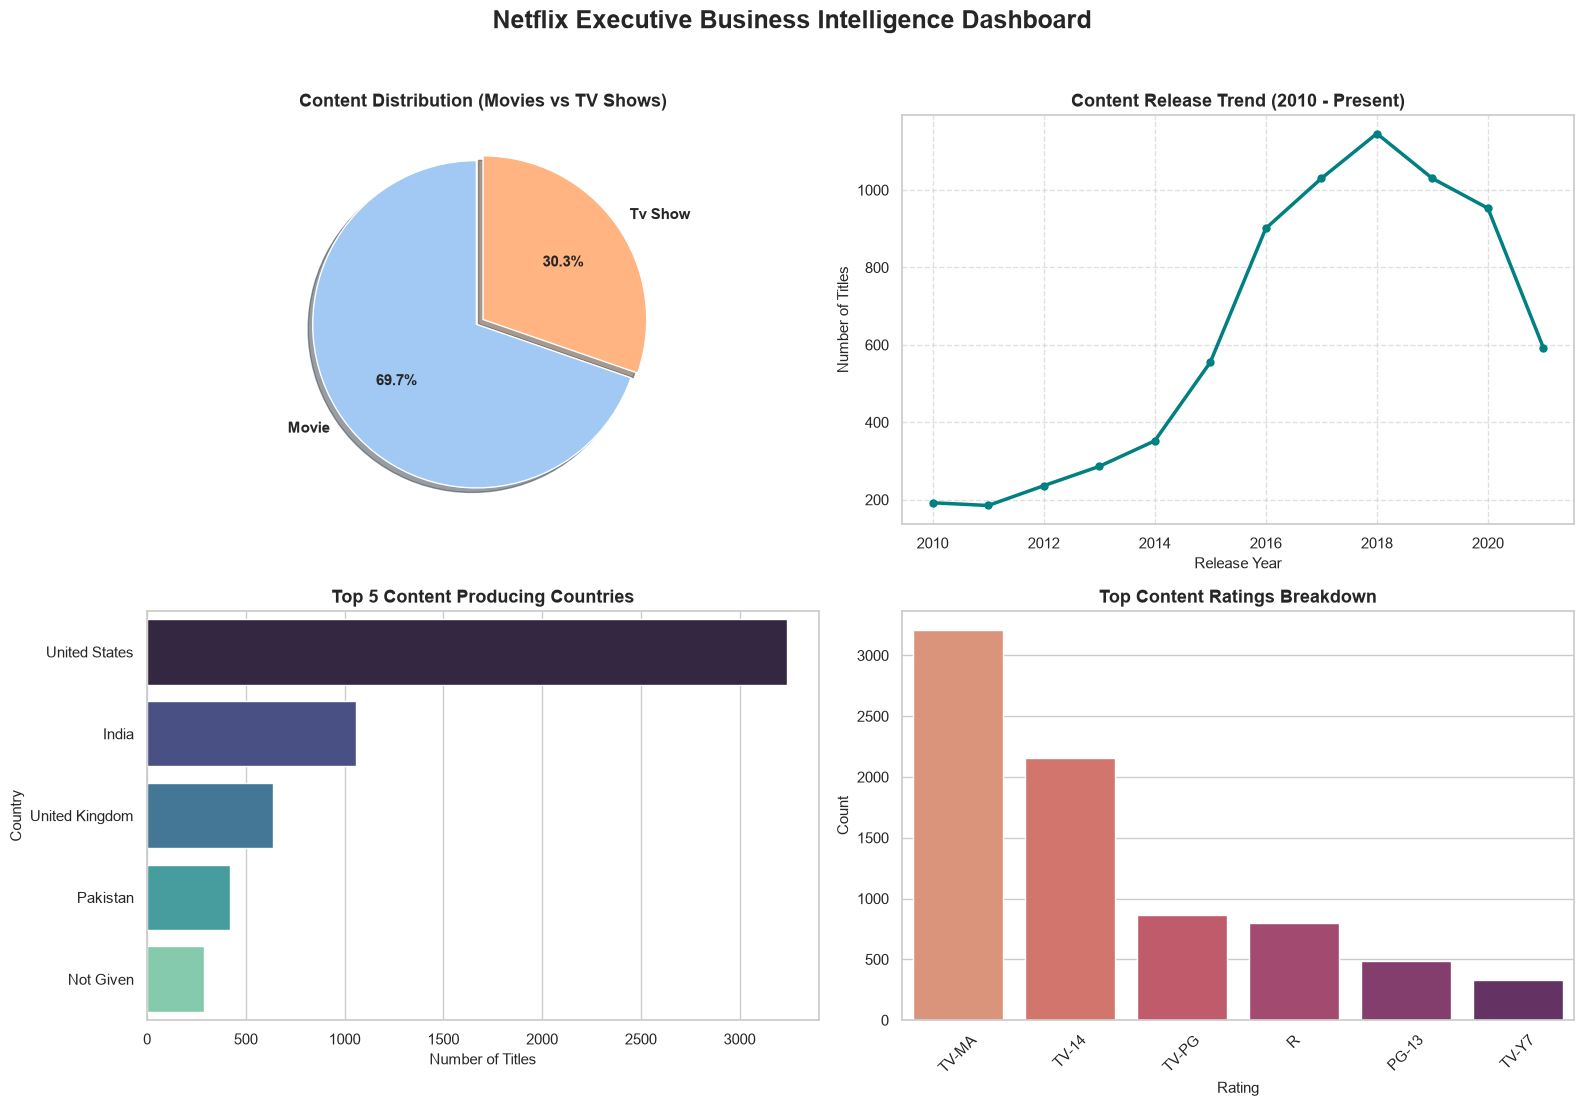


        NETFLIX EXECUTIVE BUSINESS REPORT         
1. Catalog Balance: Movies heavily outweigh TV Shows,
   representing roughly 69.7% of total catalog data.
2. Production Acceleration: Content creation scaled rapidly through the 2010s,
   reflecting a strategic transition into aggressive digital streaming acquisition.
3. Geographic Concentration: Production leadership is heavily anchored
   by primary hubs like United States and India,
   indicating strong reliance on localized production pipelines alongside US markets.
4. Audience Targeting: Ratings cluster heavily around mature adolescents and adults
   (e.g., TV-MA, TV-PG, R), steering clear of broad universal children exclusivity
   as core library focus.


In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Step 1: Perform complete exploratory data analysis & load dataset
file_path = r"C:\Users\harik\Downloads\cleaned_netflix_data.csv"
df = pd.read_csv(file_path)

print('--- Cleaned Dataset Loaded Successfully for Task 6 ---')
print(f'Total Records to Analyze: {len(df)}')

# Step 2: Identify key content trends and patterns (aggregations)
type_counts = df['type'].value_counts() if 'type' in df.columns else pd.Series()
yearly_trend = (
    df[df['release_year'] >= 2010]['release_year'].value_counts().sort_index()
    if 'release_year' in df.columns
    else pd.Series()
)
rating_counts = df['rating'].value_counts() if 'rating' in df.columns else pd.Series()

# Extract top countries
if 'country' in df.columns:
  df_country = df.dropna(subset=['country']).copy()
  df_country['country'] = df_country['country'].astype(str).str.split(',')
  top_countries = (
      df_country.explode('country')['country']
      .str.strip()
      .loc[lambda x: (x != 'Unknown') & (x != '')]
      .value_counts()
      .head(5)
  )
else:
  top_countries = pd.Series()

# Step 3: Develop multiple visual dashboards (2x2 Subplot Grid)
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    'Netflix Executive Business Intelligence Dashboard',
    fontsize=18,
    fontweight='bold',
    y=0.95,
)

# Dashboard Panel 1: Content Type Proportion
axes[0, 0].pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('pastel'),
    explode=(0.05, 0),
    shadow=True,
    textprops={'fontsize': 11, 'fontweight': 'bold'},
)
axes[0, 0].set_title(
    'Content Distribution (Movies vs TV Shows)',
    fontsize=13,
    fontweight='bold',
)

# Dashboard Panel 2: Release Year Growth Trend
axes[0, 1].plot(
    yearly_trend.index,
    yearly_trend.values,
    marker='o',
    color='teal',
    linewidth=2.5,
    markersize=5,
)
axes[0, 1].set_title(
    'Content Release Trend (2010 - Present)', fontsize=13, fontweight='bold'
)
axes[0, 1].set_xlabel('Release Year', fontsize=11)
axes[0, 1].set_ylabel('Number of Titles', fontsize=11)
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# Dashboard Panel 3: Top 5 Content-Producing Countries
sns.barplot(
    ax=axes[1, 0],
    x=top_countries.values,
    y=top_countries.index,
    palette='mako',
    hue=top_countries.index,
    legend=False,
)
axes[1, 0].set_title(
    'Top 5 Content Producing Countries', fontsize=13, fontweight='bold'
)
axes[1, 0].set_xlabel('Number of Titles', fontsize=11)
axes[1, 0].set_ylabel('Country', fontsize=11)

# Dashboard Panel 4: Top Content Ratings
top_ratings = rating_counts.head(6)
sns.barplot(
    ax=axes[1, 1],
    x=top_ratings.index,
    y=top_ratings.values,
    palette='flare',
    hue=top_ratings.index,
    legend=False,
)
axes[1, 1].set_title(
    'Top Content Ratings Breakdown', fontsize=13, fontweight='bold'
)
axes[1, 1].set_xlabel('Rating', fontsize=11)
axes[1, 1].set_ylabel('Count', fontsize=11)
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout(rect=[0, 0.03, 1, 0.93])

# Save the dashboard report image
output_dashboard_path = r"C:\Users\harik\Downloads\netflix_business_dashboard.png"
plt.savefig(output_dashboard_path, dpi=300)
print(f'\nComprehensive Dashboard saved to: {output_dashboard_path}')
plt.show()

# Step 4 & 5: Generate actionable business insights & executive summary
print('\n==================================================')
print('        NETFLIX EXECUTIVE BUSINESS REPORT         ')
print('==================================================')
print(f'1. Catalog Balance: Movies heavily outweigh TV Shows,')
print(
    f'   representing roughly {(type_counts.get("Movie", 0)/len(df))*100:.1f}%'
    ' of total catalog data.'
)
print(
    '2. Production Acceleration: Content creation scaled rapidly through'
    ' the 2010s,'
)
print(
    '   reflecting a strategic transition into aggressive digital streaming'
    ' acquisition.'
)
print(
    '3. Geographic Concentration: Production leadership is heavily anchored'
)
print(
    f'   by primary hubs like {top_countries.index[0]} and'
    f' {top_countries.index[1]},'
)
print(
    '   indicating strong reliance on localized production pipelines alongside'
    ' US markets.'
)
print(
    '4. Audience Targeting: Ratings cluster heavily around mature'
    ' adolescents and adults'
)
print(
    '   (e.g., TV-MA, TV-PG, R), steering clear of broad universal children'
    ' exclusivity'
)
print('   as core library focus.')
print('==================================================')